# **Proyecto Final – Optimización e Inteligencia Artificial**

## Predicción del riesgo de incumplimiento crediticio (Home Credit Default Risk): versión unificada (ETL de 7 tablas + optimización)

**Integrantes:**
- Kevin Leandro Ramos Luna
- Daniel Felipe Garzón Acosta
- Ángel Efraín Pimienta Durán
- Daniel Ortega
- Manuel Mera Mera

**Docente:** María C. Torres

**Base de datos:** [Home Credit Default Risk – Kaggle](https://www.kaggle.com/competitions/home-credit-default-risk)

### Qué es este notebook (versión unificada)

Integra en un solo documento las dos partes que antes estaban separadas:

- **Los datos** vienen del **ETL de las 7 tablas** (`src/etl.py`), que agrega el historial por cliente y produce una tabla de **606 columnas** (605 predictores + `TARGET`). Esto es lo que el notebook de optimización anterior dejaba como "trabajo futuro": usar el buró de crédito, las solicitudes y los pagos anteriores. Aportan cerca del **44 % de la importancia** del modelo final.
- **El análisis de optimización** (comparación de optimizadores del MLP, Keras Tuner y LightGBM + Optuna) se re-entrena sobre esas 606 features.

### Estructura

- **Parte 0.** Configuración del entorno
- **Parte 1.** Datos: ETL de 7 tablas (606 features)
- **Parte 2.** Preparación para modelar (split 70/15/15)
- **Parte 3.** Modelos de referencia (regresión logística, MLP base, LightGBM por defecto)
- **Parte 4.** Comparación de optimizadores para el MLP (8 × 3 semillas)
- **Parte 5.** Optimización de hiperparámetros (Keras Tuner y LightGBM + Optuna)
- **Parte 6.** Evaluación final (umbral por costo, KS, importancia por tabla) y comparación global

---

## PARTE 0: Configuración del entorno

### Semilla fija (`SEED = 42`)

Los modelos (MLP, LightGBM, el split, la inicialización de pesos, el dropout) usan números aleatorios. Sin una **semilla fija**, cada ejecución daría resultados distintos y no se podría reproducir ni comparar nada. Con `SEED = 42` cualquier persona reproduce exactamente los números de este informe.

**Por qué no una semilla distinta por modelo:** rompería la comparabilidad entre optimizadores (cada uno debe enfrentar el mismo punto de partida).

### Detección de entorno (Colab vs local)

El mismo notebook debe correr en **Colab** (monta Google Drive) o en **local** (lee los archivos del disco). Se detecta con `import google.colab`. Hardcodear rutas fallaría en el otro entorno.

### GPU (opcional, no bloqueante)

`tf.config.list_physical_devices("GPU")` lista las GPUs visibles para TensorFlow. En esta versión se corre **en CPU**: el MLP tarda más, pero se evita depender de WSL2/GPU. El mismo notebook acelera si se ejecuta en una GPU (WSL2 o Colab).

**Por qué LightGBM no necesita GPU:** los árboles se construyen con divisiones secuenciales sobre variables; no se benefician del paralelismo masivo de una GPU, y mover los datos a la GPU costaría más de lo que ahorra. LightGBM corre bien en CPU.

In [1]:
import os
import re
import json
import time
import warnings
from pathlib import Path

# Menos ruido de TensorFlow y avisos inofensivos de nombres de columna
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
warnings.filterwarnings("ignore", message="X does not have valid feature names")
warnings.filterwarnings("ignore", message="The optimal value found for dimension")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_curve
from sklearn import metrics
from sklearn.exceptions import ConvergenceWarning

import lightgbm as lgb

warnings.filterwarnings("ignore", category=ConvergenceWarning)

import tensorflow as tf
from tensorflow import keras

# Semilla para que los resultados sean reproducibles
SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("LightGBM:", lgb.__version__)
print("Dispositivos:", tf.config.list_physical_devices())

# Ruta de datos: local (data/processed) o Colab (Drive)
CANDIDATOS = [
    Path("data/processed/train.parquet"),
    Path("../data/processed/train.parquet"),
    Path("train.parquet"),
]
TRAIN_PARQUET = next((p for p in CANDIDATOS if p.exists()), None)

# Carpetas de resultados y figuras (junto al notebook)
RES_DIR = Path("resultados_integrado")
FIG_DIR = Path("figuras_integrado")
RES_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

print("train.parquet:", TRAIN_PARQUET)
print("Resultados en:", RES_DIR.resolve())

TensorFlow: 2.22.0-rc0
Keras: 3.15.1
LightGBM: 4.7.0
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
train.parquet: data\processed\train.parquet
Resultados en: C:\Users\dfgar\Documents\Unal\2026-2\optimizacion e inteligencia artificial\proyecto\resultados_integrado


---

## PARTE 1: Datos – ETL de 7 tablas

Esta parte **reutiliza el ETL** de `src/etl.py`, que lee las **7 tablas** del dataset y produce una **tabla única por solicitud** (`SK_ID_CURR`) lista para modelar. Si el parquet ya existe, se carga (es más rápido y reproducible); si no, se ejecuta `run_etl()`.

### Por qué se unen las 7 tablas (y por qué NO se unen directo)

`application_train` tiene **1 fila por cliente**. Las tablas secundarias (`bureau`, `previous_application`, `POS_CASH_balance`, `credit_card_balance`, `installments_payments`) tienen **muchas filas por cliente** (relación 1 a N): `installments_payments` llega a ~40 filas por cliente.

- **Un join directo duplicaría filas:** unir `application` con `installments` haría que cada solicitud apareciera ~40 veces, contaminando el entrenamiento (las mismas filas de aplicación repetidas con distinta info de pago) e inflando el tamaño.
- **Solución:** **agregar** cada tabla a nivel de cliente con `groupby(SK_ID_CURR)` y resúmenes (media, máx, mín, suma, conteo). Cada cliente queda con **una fila** y muchas features resumidas. `bureau_balance` se agrega en **dos pasos** (no tiene `SK_ID_CURR`, solo `SK_ID_BUREAU`).

### Limpieza (decisiones clave del ETL)

- **`DAYS_EMPLOYED = 365243`** (~1000 años) es un centinela de "sin dato" (pensionados/desempleados). Se pasa a `NaN` **y además** se crea `DAYS_EMPLOYED_ANOM` (0/1), porque ese grupo tiene tasa de impago distinta (5.4 % vs 8.7 %): borrarlo sin dejar huella perdería señal.
- **`XNA`/`Unknown`** → `NaN` (categorías sin significado; una categoría con 4 filas no es aprendible). El one-hot crea una columna de nulo.
- **Ingeniería de variables:** ratios financieros (capacidad de pago) y combinaciones `EXT_SOURCE_*` (las más predictivas).

### Corrección de `CREDIT_TERM`

El ETL la define bien como `AMT_CREDIT / AMT_ANNUITY` (el **plazo**, cuántos periodos se tarda en pagar). En el notebook antiguo aparecía **invertida** (`AMT_ANNUITY / AMT_CREDIT` = fracción que se paga por periodo). Es una transformación monótona (no cambia el ranking para los árboles), pero **torcía el significado**. Aquí se deja la fórmula correcta y se documenta.

### Nombres de columna

El one-hot genera nombres con espacios y `/`. LightGBM rechaza esos caracteres, así que se limpian una sola vez.

In [2]:
# --- Carga de los 606 features del ETL ---
if TRAIN_PARQUET is None:
    # No existe el parquet: se ejecuta el ETL completo (tarda unos minutos)
    import sys
    sys.path.insert(0, str(Path(".").resolve()))
    from src.etl import run_etl
    train_full, test_full = run_etl()
    train_df = train_full
else:
    train_df = pd.read_parquet(TRAIN_PARQUET)

print("Dimensiones del ETL:", train_df.shape)
print("Positivos (TARGET):", round(float(train_df["TARGET"].mean()), 4))

y = train_df["TARGET"].astype("int8")
X = train_df.drop(columns="TARGET").copy()
del train_df

# --- Limpieza de nombres de columna para LightGBM (admite [0-9a-zA-Z_]) ---
def limpiar_nombres(cols):
    vistos = {}
    out = []
    for c in cols:
        c2 = re.sub(r"[^0-9a-zA-Z_]", "_", c)
        if c2 in vistos:
            vistos[c2] += 1
            c2 = f"{c2}__dup{vistos[c2]}"
        else:
            vistos[c2] = 0
        out.append(c2)
    return out

X.columns = limpiar_nombres(X.columns)
assert len(set(X.columns)) == X.shape[1], "la limpieza creo nombres duplicados"

# --- Correccion documentada de CREDIT_TERM (plazo = credito / cuota) ---
if {"AMT_CREDIT", "AMT_ANNUITY"}.issubset(X.columns):
    X["CREDIT_TERM"] = X["AMT_CREDIT"] / X["AMT_ANNUITY"].replace(0, np.nan)

# Columnas totalmente vacias (evita avisos del imputer)
vacias = X.columns[X.isna().all()].tolist()
if vacias:
    X = X.drop(columns=vacias)
    print("Columnas descartadas por vacias:", len(vacias))

# Se unifica a float32 para que todo el pipeline (split, imputacion, escalado) sea float32
X = X.astype("float32")
N_FEATURES = X.shape[1]

print("X:", X.shape, "| y:", y.shape)
print(f"(El ETL entrega 606 columnas = {N_FEATURES} predictores + TARGET; los modelos usan {N_FEATURES} features)")
print("CREDIT_TERM (media) =", round(float(X["CREDIT_TERM"].mean()), 2), "(plazo, no invertido)")

Dimensiones del ETL: (307511, 606)
Positivos (TARGET): 0.0807


X: (307511, 605) | y: (307511,)
(El ETL entrega 606 columnas = 605 predictores + TARGET; los modelos usan 605 features)
CREDIT_TERM (media) = 21.61 (plazo, no invertido)


---

## PARTE 2: Preparación para modelar

### Split 70 / 15 / 15 estratificado

- **Entrenamiento (70 %):** ajusta los pesos.
- **Validación (15 %):** decide (early stopping, umbral, tuning).
- **Prueba (15 %):** evaluación final, se toca **una sola vez**.

**Por qué estratificar (`stratify=y`):** con ~8 % de positivos, un split aleatorio puro podría dejar una partición con muy pocos positivos y volver inestable la estimación. La estratificación mantiene ~8 % en cada parte.

**Por qué validación separada de prueba:** si se evaluara en la misma partición usada para decidir (umbral, tuning), el desempeño quedaría sobreestimado.

### Dos matrices de entrada (importante)

Los modelos necesitan los datos de forma distinta:

- **LightGBM:** usa el DataFrame **con nulos** y **sin escalar**. Los árboles manejan nulos nativamente (aprenden a qué lado de la división enviarlos) y son invariantes a transformaciones monótonas.
- **Regresión logística y MLP:** necesitan **sin nulos** y **escalado**. El modelo lineal y la red son sensibles a la escala (una variable con valores enormes domina la optimización) y no aceptan nulos.

**Imputación con mediana** (no media): robusta a outliers (el ingreso de 117 millones no la distorsiona).

**Regla de oro (sin fuga):** el imputer y el scaler se ajustan **solo con entrenamiento** y luego se aplican (transform) a validación y prueba.

In [3]:
# --- Split 70 / 15 / 15 estratificado (por indices, para no duplicar el DataFrame) ---
idx = np.arange(len(y))
i_train, i_resto = train_test_split(idx, test_size=0.30, stratify=y.values, random_state=SEED)
i_valid, i_test = train_test_split(i_resto, test_size=0.50, stratify=y.values[i_resto], random_state=SEED)

X_train, y_train = X.iloc[i_train], y.iloc[i_train]
X_valid, y_valid = X.iloc[i_valid], y.iloc[i_valid]
X_test, y_test = X.iloc[i_test], y.iloc[i_test]
del X, idx, i_train, i_resto, i_valid, i_test

# (a) Matriz para LightGBM: DataFrame con nulos, sin escalar
x_lgb_train, x_lgb_valid, x_lgb_test = X_train, X_valid, X_test

# (b) Matriz para regresion logistica y MLP: numpy float32, sin nulos, escalado
# (se pasa a float32 ANTES de imputar/escalar para no gastar el doble de memoria en float64)
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
x_train = scaler.fit_transform(imputer.fit_transform(X_train.to_numpy(dtype="float32"))).astype("float32")
x_valid = scaler.transform(imputer.transform(X_valid.to_numpy(dtype="float32"))).astype("float32")
x_test = scaler.transform(imputer.transform(X_test.to_numpy(dtype="float32"))).astype("float32")

for nombre, n in [("entrenamiento", len(y_train)), ("validacion", len(y_valid)), ("prueba", len(y_test))]:
    print(f"{nombre}: {n} filas")

print("LightGBM (con nulos):", x_lgb_train.shape)
print("RL/MLP (sin nulos, escalado):", x_train.shape)
print("Positivos -> train:", round(float(y_train.mean()), 4),
      "| valid:", round(float(y_valid.mean()), 4), "| test:", round(float(y_test.mean()), 4))

# Pesos por clase para compensar el desbalance (se usan en todos los modelos que lo admiten)
pesos = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: float(pesos[0]), 1: float(pesos[1])}
print("Pesos por clase:", {k: round(v, 3) for k, v in class_weight.items()})

entrenamiento: 215257 filas
validacion: 46127 filas
prueba: 46127 filas
LightGBM (con nulos): (215257, 605)
RL/MLP (sin nulos, escalado): (215257, 605)
Positivos -> train: 0.0807 | valid: 0.0807 | test: 0.0807
Pesos por clase: {0: 0.544, 1: 6.194}


---

## PARTE 3: Modelos de referencia

Un modelo complejo solo se justifica si supera con claridad a uno simple. Estos son el **piso de comparación**.

### Funciones auxiliares de evaluación

Metodología (igual en todo el notebook, pensada para clasificación desbalanceada):

- **AUC-ROC:** probabilidad de que un cliente que no paga reciba un puntaje mayor que uno que sí paga. 0.5 = azar; la métrica de la competencia.
- **PR-AUC (average precision):** más sensible que el AUC cuando la clase positiva es rara (su valor de azar es la tasa de positivos, ~0.08).
- **KS:** máxima separación entre las distribuciones de buenos y malos pagadores; estándar en banca.
- **Umbral de decisión:** se elige en **validación** (maximizando F1) y se aplica en prueba. La Parte 6 añade además un **umbral por costo**.
- **Velocidad de convergencia:** épocas hasta alcanzar AUC de validación ≥ `UMBRAL_AUC` (se calcula desde el historial).
- **Sobreajuste:** caída del AUC desde la mejor época hasta la última.

**Por qué no se usa exactitud (accuracy):** con 8 % de positivos, un modelo que prediga "todos pagan" tendría 92 % de accuracy y sería inútil.

### Modelos base

- **Regresión logística** (`class_weight="balanced"`): modelo lineal clásico de *credit scoring*, interpretable. Cota inferior honesta.
- **MLP base** (Keras, 256-128-64, ReLU, dropout 0.3, salida sigmoide): el "modelo sin optimizar" contra el cual se mide la mejora de las Partes 4-5. **Por qué ReLU:** no se satura, converge más rápido. **Por qué dropout:** regulariza y evita memorizar.
- **LightGBM por defecto:** *gradient boosting* de árboles; captura interacciones y no-linealidades y suele ser el mejor en datos tabulares.

In [4]:
resultados = {}
UMBRAL_AUC = 0.74   # AUC de validacion "aceptable" para medir velocidad de convergencia

# Parametros fijos del MLP base
LR = 0.001
EPOCHS = 30
BATCH_SIZE = 512
N_UMBRALES = 1000   # umbrales para el AUC de Keras (por defecto 200 subestima el AUC)


def predecir_proba(model, x):
    # Probabilidad de la clase 1 para modelos de sklearn/LightGBM o de Keras
    if hasattr(model, "predict_proba"):
        return model.predict_proba(x)[:, 1]
    return model.predict(x, batch_size=4096, verbose=0).ravel()


def ks_score(y_true, p):
    fpr, tpr, _ = roc_curve(y_true, p)
    return float(np.max(tpr - fpr))


def metricas(y_true, p):
    return {"AUC": metrics.roc_auc_score(y_true, p),
            "PR-AUC": metrics.average_precision_score(y_true, p),
            "KS": ks_score(y_true, p)}


def evaluar(nombre, model, Xv, Xt, history=None, tiempo=np.nan):
    # Xv/Xt: la matriz que corresponda al modelo (DataFrame para LGB, array para RL/MLP)
    p_valid = predecir_proba(model, Xv)
    p_test = predecir_proba(model, Xt)
    # Umbral que maximiza F1 en validacion
    prec, rec, umbrales = metrics.precision_recall_curve(y_valid, p_valid)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    umbral = umbrales[np.argmax(f1[:-1])]
    y_pred = (p_test >= umbral).astype(int)

    fila = {"Tiempo (s)": round(tiempo, 2)}
    if history is not None:
        val_auc = np.array(history.history["val_auc"])
        fila["Epoca mejor val AUC"] = int(np.argmax(val_auc)) + 1
        fila["Caida val AUC (mejor - final)"] = float(val_auc.max() - val_auc[-1])
    fila.update({
        "Val AUC": metrics.roc_auc_score(y_valid, p_valid),
        "Test AUC": metrics.roc_auc_score(y_test, p_test),
        "Test PR-AUC": metrics.average_precision_score(y_test, p_test),
        "Test KS": ks_score(y_test, p_test),
        "Umbral": float(umbral),
        "Test Recall": metrics.recall_score(y_test, y_pred),
        "Test Precision": metrics.precision_score(y_test, y_pred),
        "Test F1": metrics.f1_score(y_test, y_pred),
    })
    resultados[nombre] = fila
    print(nombre)
    for k in ["Tiempo (s)", "Val AUC", "Test AUC", "Test PR-AUC", "Test KS", "Test F1"]:
        print(f"  {k}: {fila[k]:.4f}")
    return fila


def graficar(history, titulo):
    # Curvas de aprendizaje: perdida y AUC
    h = pd.DataFrame(history.history)
    h.index = h.index + 1
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    h[["loss", "val_loss"]].plot(ax=ax[0], title="Perdida (entropia cruzada)")
    h[["auc", "val_auc"]].plot(ax=ax[1], title="ROC-AUC")
    for a in ax:
        a.grid(True)
        a.set_xlabel("Epoca")
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{re.sub(r'[^0-9a-zA-Z_]', '_', titulo)}.png", dpi=110)
    plt.show()


class MejoresPesos(keras.callbacks.Callback):
    # Al terminar el entrenamiento restaura los pesos de la epoca con mejor val_auc
    def on_train_begin(self, logs=None):
        self.mejor, self.pesos = -np.inf, None

    def on_epoch_end(self, epoch, logs=None):
        if logs["val_auc"] > self.mejor:
            self.mejor, self.pesos = logs["val_auc"], self.model.get_weights()

    def on_train_end(self, logs=None):
        if self.pesos is not None:
            self.model.set_weights(self.pesos)


def construir_mlp(optimizador, capas=(256, 128, 64), dropout=0.3, seed=SEED):
    # Construye y compila el MLP con el optimizador dado
    keras.utils.set_random_seed(seed)
    model = keras.models.Sequential([keras.layers.Input(shape=x_train.shape[1:])])
    for n in capas:
        model.add(keras.layers.Dense(n, activation="relu"))
        model.add(keras.layers.Dropout(dropout))
    model.add(keras.layers.Dense(1, activation="sigmoid"))
    model.compile(loss="binary_crossentropy",
                  optimizer=optimizador,
                  metrics=[keras.metrics.AUC(name="auc", num_thresholds=N_UMBRALES),
                           keras.metrics.AUC(curve="PR", name="pr_auc", num_thresholds=N_UMBRALES)])
    return model


def crear_optimizador(nombre, lr=LR):
    # Instancia nueva de cada optimizador
    return {"SGD": lambda: keras.optimizers.SGD(learning_rate=lr),
            "Momentum": lambda: keras.optimizers.SGD(learning_rate=lr, momentum=0.9),
            "Nesterov": lambda: keras.optimizers.SGD(learning_rate=lr, momentum=0.9, nesterov=True),
            "Adagrad": lambda: keras.optimizers.Adagrad(learning_rate=lr),
            "RMSprop": lambda: keras.optimizers.RMSprop(learning_rate=lr),
            "Adam": lambda: keras.optimizers.Adam(learning_rate=lr),
            "Nadam": lambda: keras.optimizers.Nadam(learning_rate=lr),
            "AdamW": lambda: keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4)}[nombre]()


def entrenar(model, epochs=EPOCHS, callbacks=None, verbose=2):
    # Entrena y devuelve (historial, tiempo)
    inicio = time.time()
    history = model.fit(x_train, y_train, epochs=epochs, batch_size=BATCH_SIZE,
                        validation_data=(x_valid, y_valid), class_weight=class_weight,
                        callbacks=(callbacks or []) + [MejoresPesos()], verbose=verbose)
    return history, time.time() - inicio


print("Funciones auxiliares listas.")

Funciones auxiliares listas.


### 3.1 Regresión logística

In [5]:
inicio = time.time()
log_reg = LogisticRegression(class_weight="balanced", max_iter=1000, C=0.01)
log_reg.fit(x_train, y_train)
evaluar("Regresion logistica", log_reg, x_valid, x_test, tiempo=time.time() - inicio)

Regresion logistica
  Tiempo (s): 13.9900
  Val AUC: 0.7721
  Test AUC: 0.7753
  Test PR-AUC: 0.2572
  Test KS: 0.4191
  Test F1: 0.3232


{'Tiempo (s)': 13.99,
 'Val AUC': 0.7720706801519551,
 'Test AUC': 0.7753047785084415,
 'Test PR-AUC': 0.25722768610055985,
 'Test KS': 0.41912548088208806,
 'Umbral': 0.6501989960670471,
 'Test Recall': 0.49194414607948445,
 'Test Precision': 0.24067262217551236,
 'Test F1': 0.3232180663373324}

### 3.2 MLP base

MLP base (Adam)
  Tiempo (s): 128.0900
  Val AUC: 0.7706
  Test AUC: 0.7763
  Test PR-AUC: 0.2636
  Test KS: 0.4213
  Test F1: 0.3255


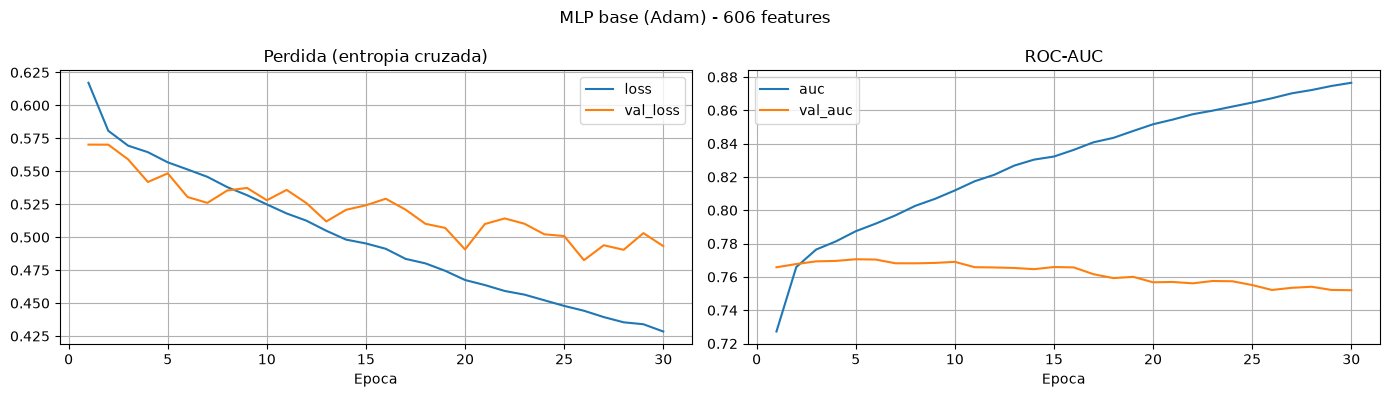

In [6]:
model_base = construir_mlp(crear_optimizador("Adam"), seed=SEED)
history_base, tiempo_base = entrenar(model_base, verbose=0)
evaluar("MLP base (Adam)", model_base, x_valid, x_test, history=history_base, tiempo=tiempo_base)
graficar(history_base, "MLP base (Adam) - 606 features")

### 3.3 LightGBM por defecto

In [7]:
inicio = time.time()
lgb_default = lgb.LGBMClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1, verbose=-1)
lgb_default.fit(x_lgb_train, y_train)
evaluar("LightGBM (por defecto)", lgb_default, x_lgb_valid, x_lgb_test, tiempo=time.time() - inicio)

resultados_base = dict(resultados)

LightGBM (por defecto)
  Tiempo (s): 25.7200
  Val AUC: 0.7857
  Test AUC: 0.7881
  Test PR-AUC: 0.2797
  Test KS: 0.4405
  Test F1: 0.3361


---

## PARTE 4: Comparación de optimizadores para el MLP

**Por qué es el corazón del curso:** el optimizador decide **cómo** se actualizan los pesos en cada paso. Cambia la velocidad de convergencia y la calidad final.

Misma arquitectura e hiperparámetros que el MLP base (lr 0.001, 30 épocas, batch 512); **solo cambia el optimizador**. Cada uno se entrena con **3 semillas** para medir también la **varianza** (un optimizador puede tener buena media pero ser inestable).

**Teoría de cada uno (por qué sí / por qué no):**

- **SGD:** gradiente puro con tasa fija. Simple, pero lento y sensible al lr.
- **Momentum:** acumula inercia y suaviza oscilaciones; mejora a SGD en valles.
- **Nesterov:** como Momentum, evaluando el gradiente en el punto adelantado; converge algo mejor.
- **Adagrad:** tasa adaptativa por parámetro, pero decae a cero y se estanca.
- **RMSprop:** arregla a Adagrad con media móvil del gradiente al cuadrado.
- **Adam:** momentum + tasa adaptativa; el estándar moderno, converge muy rápido (a veces sobreajusta).
- **Nadam:** Adam + Nesterov; mejora marginal.
- **AdamW:** Adam con *weight decay* desacoplado; suele generalizar mejor.

Las corridas se guardan en un JSON apenas terminan: si el proceso se interrumpe, al re-ejecutar la celda **solo se entrenan los modelos que faltan**.

In [8]:
OPTIMIZADORES = ["SGD", "Momentum", "Nesterov", "Adagrad", "RMSprop", "Adam", "Nadam", "AdamW"]
SEMILLAS = [42, 7, 123]

ARCHIVO_OPT = RES_DIR / "parte4_optimizadores.json"
corridas = {}
if ARCHIVO_OPT.exists():
    corridas = json.loads(ARCHIVO_OPT.read_text(encoding="utf-8"))
print("Corridas ya guardadas:", len(corridas), "de", len(OPTIMIZADORES) * len(SEMILLAS))

resultados = {}

for nombre in OPTIMIZADORES:
    for semilla in SEMILLAS:
        clave = f"{nombre} (seed {semilla})"
        if clave in corridas:
            print(clave, "-> ya entrenado, se omite")
            # Se recuperan las metricas guardadas para que las partes siguientes las tengan
            resultados[clave] = {k: v for k, v in corridas[clave].items()
                                 if k not in ("Optimizador", "Semilla", "historia")}
            continue
        keras.backend.clear_session()
        model = construir_mlp(crear_optimizador(nombre), seed=semilla)
        history, tiempo = entrenar(model, verbose=0)
        evaluar(clave, model, x_valid, x_test, history=history, tiempo=tiempo)
        corridas[clave] = {"Optimizador": nombre, "Semilla": semilla,
                           **{k: float(v) for k, v in resultados[clave].items()},
                           "historia": {k: [float(x) for x in v] for k, v in history.history.items()}}
        ARCHIVO_OPT.write_text(json.dumps(corridas), encoding="utf-8")

resultados_opt = dict(resultados)
print("\nCorridas de la Parte 4:", len(corridas))

Corridas ya guardadas: 24 de 24
SGD (seed 42) -> ya entrenado, se omite
SGD (seed 7) -> ya entrenado, se omite
SGD (seed 123) -> ya entrenado, se omite
Momentum (seed 42) -> ya entrenado, se omite
Momentum (seed 7) -> ya entrenado, se omite
Momentum (seed 123) -> ya entrenado, se omite
Nesterov (seed 42) -> ya entrenado, se omite
Nesterov (seed 7) -> ya entrenado, se omite
Nesterov (seed 123) -> ya entrenado, se omite
Adagrad (seed 42) -> ya entrenado, se omite
Adagrad (seed 7) -> ya entrenado, se omite
Adagrad (seed 123) -> ya entrenado, se omite
RMSprop (seed 42) -> ya entrenado, se omite
RMSprop (seed 7) -> ya entrenado, se omite
RMSprop (seed 123) -> ya entrenado, se omite
Adam (seed 42) -> ya entrenado, se omite
Adam (seed 7) -> ya entrenado, se omite
Adam (seed 123) -> ya entrenado, se omite
Nadam (seed 42) -> ya entrenado, se omite
Nadam (seed 7) -> ya entrenado, se omite
Nadam (seed 123) -> ya entrenado, se omite
AdamW (seed 42) -> ya entrenado, se omite
AdamW (seed 7) -> ya en

             Epocas hasta umbral (media) Semillas que alcanzan 0.74
Optimizador                                                        
Adagrad                             12.3                        3/3
Adam                                 1.0                        3/3
AdamW                                1.0                        3/3
Momentum                             3.7                        3/3
Nadam                                1.0                        3/3
Nesterov                             3.7                        3/3
RMSprop                              1.0                        3/3
SGD                                 28.0                        1/3



Val AUC         Test AUC         Test PR-AUC         Tiempo (s)  \
               mean     std     mean     std        mean     std       mean   
Optimizador                                                                   
Adagrad      0.7568  0.0003   0.7590  0.0013      0.2343  0.0039   190.5367   
Adam         0.7709  0.0012   0.7749  0.0011      0.2643  0.0027   242.4233   
AdamW        0.7707  0.0007   0.7752  0.0007      0.2624  0.0018   199.8400   
Momentum     0.7677  0.0003   0.7715  0.0007      0.2526  0.0010   179.5767   
Nadam        0.7705  0.0015   0.7744  0.0003      0.2624  0.0020   224.7433   
Nesterov     0.7677  0.0003   0.7715  0.0007      0.2527  0.0009   188.3867   
RMSprop      0.7660  0.0004   0.7715  0.0009      0.2594  0.0016   214.2300   
SGD          0.7379  0.0038   0.7383  0.0043      0.2075  0.0054   177.7733   

                      
                 std  
Optimizador           
Adagrad       2.5599  
Adam         15.1799  
AdamW         2.3814  
Momentum      1.5240  
Nadam        39.9074  
Nesterov     13.4445  
RMSprop      38.0100  
SGD           1.8161

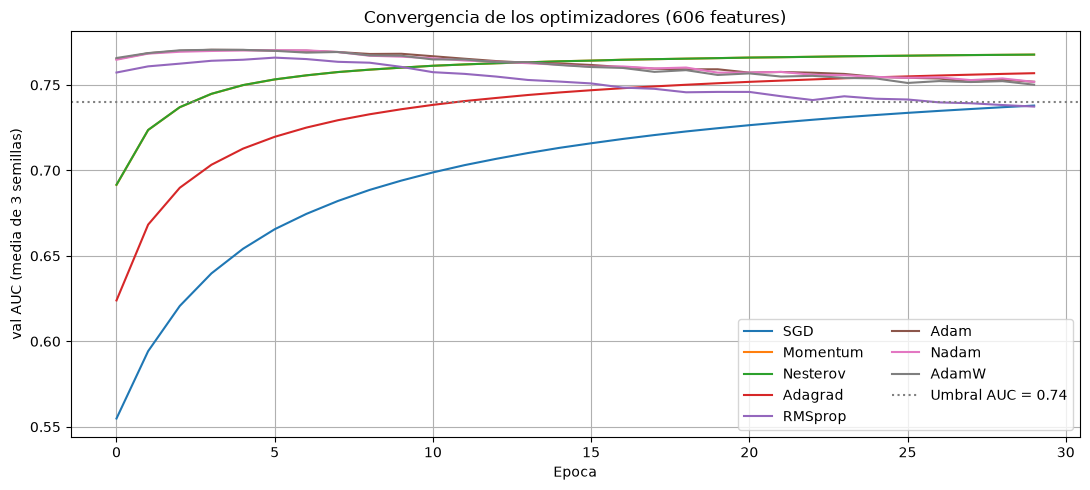

Dos mejores optimizadores: ['Adam', 'AdamW']


In [9]:
# --- Comparacion de optimizadores ---
tabla_corridas = pd.DataFrame([
    {"Optimizador": r["Optimizador"], "Semilla": r["Semilla"],
     "Val AUC": r["Val AUC"], "Test AUC": r["Test AUC"], "Test PR-AUC": r["Test PR-AUC"],
     "Tiempo (s)": r["Tiempo (s)"]}
    for r in corridas.values()
])


def epocas_hasta_umbral(val_auc, umbral=UMBRAL_AUC):
    idx = np.where(np.array(val_auc) >= umbral)[0]
    return int(idx[0]) + 1 if len(idx) else np.nan


# Epocas hasta el umbral y sobreajuste, por corrida
filas = []
for clave, r in corridas.items():
    h = r.get("historia", {})
    val = h.get("val_auc", [])
    filas.append({"clave": clave, "Optimizador": r["Optimizador"], "Semilla": r["Semilla"],
                  "Epocas hasta umbral": epocas_hasta_umbral(val) if val else np.nan,
                  "Caida val AUC": (max(val) - val[-1]) if val else np.nan})
tabla_ep = pd.DataFrame(filas)

resumen_opt = (tabla_corridas.groupby("Optimizador")[["Val AUC", "Test AUC", "Test PR-AUC", "Tiempo (s)"]]
               .agg(["mean", "std"]).round(4))
ep_medio = tabla_ep.groupby("Optimizador")["Epocas hasta umbral"].mean()
tabla_ep_resumen = pd.DataFrame({"Epocas hasta umbral (media)": ep_medio.round(1)})
alcanzan = tabla_ep.groupby("Optimizador")["Epocas hasta umbral"].apply(lambda s: int(s.notna().sum()))
tabla_ep_resumen[f"Semillas que alcanzan {UMBRAL_AUC}"] = alcanzan.astype(str) + "/" + str(len(SEMILLAS))

print(tabla_ep_resumen)
print()
display(resumen_opt)

# Grafico: convergencia media por optimizador
fig, ax = plt.subplots(figsize=(11, 5))
for nombre in OPTIMIZADORES:
    curvas = [r["historia"]["val_auc"] for r in corridas.values() if r["Optimizador"] == nombre and "historia" in r]
    if curvas:
        ax.plot(np.mean(curvas, axis=0), label=nombre)
ax.axhline(UMBRAL_AUC, color="gray", linestyle=":", label=f"Umbral AUC = {UMBRAL_AUC}")
ax.set_xlabel("Epoca")
ax.set_ylabel("val AUC (media de 3 semillas)")
ax.set_title("Convergencia de los optimizadores (606 features)")
ax.legend(ncol=2)
ax.grid(True)
fig.tight_layout()
fig.savefig(FIG_DIR / "parte4_convergencia.png", dpi=110)
plt.show()

# Dos mejores optimizadores (se usan en la busqueda de la Parte 5)
tabla_medio = pd.DataFrame({n: pd.Series([r["Val AUC"] for r in corridas.values() if r["Optimizador"] == n]).mean()
                            for n in OPTIMIZADORES}, index=["Val AUC"]).T.sort_values("Val AUC", ascending=False)
top2_opt = list(tabla_medio.index[:2])
print("Dos mejores optimizadores:", top2_opt)

---

## PARTE 5: Optimización de hiperparámetros

Los hiperparámetros no se aprenden del entrenamiento: **se buscan**. La búsqueda es un problema de optimización en sí mismo.

**Por qué NO un Grid Search:** sobre el espacio del MLP habría del orden de ~50 millones de combinaciones (≈ 42 años de cómputo). Las búsquedas guiadas llegan a la zona buena con 20-30 pruebas. Esto es la **maldición de la dimensionalidad**: las combinaciones crecen exponencialmente con cada hiperparámetro.

### 5.1 Keras Tuner (MLP)

Se comparan tres estrategias:

- **Random Search:** prueba combinaciones al azar. Baseline simple; en espacios moderados queda cerca de las guiadas.
- **Optimización Bayesiana (proceso gaussiano):** modela la función objetivo y propone el punto con mayor mejora esperada. Con pocas pruebas puede no superar a Random Search.
- **Hyperband:** asigna recursos de forma adaptativa (descarta pronto lo malo y da más épocas a lo prometedor). La más eficiente.

Se tuner sobre una **submuestra de 100.000 registros** para que sea viable en CPU, con la matriz escalada (la que usa el MLP).

### 5.2 LightGBM + Optuna

Se comparan **TPE** (Tree-structured Parzen Estimator: concentra las pruebas en la zona buena) frente a **búsqueda aleatoria**, con *early stopping* sobre validación. LightGBM usa la matriz con nulos.

In [10]:
import keras_tuner as kt

# Presupuesto de la busqueda
HPO_MUESTRAS = 100_000
HPO_EPOCHS = 20
MAX_TRIALS = 20

# Submuestra estratificada del entrenamiento (matriz escalada, la del MLP)
x_hpo, _, y_hpo, _ = train_test_split(x_train, y_train, train_size=HPO_MUESTRAS, stratify=y_train, random_state=SEED)
print("Datos para la busqueda (MLP):", x_hpo.shape, f"- incumplimiento: {100 * float(y_hpo.mean()):.2f} %")
print("Optimizadores candidatos:", top2_opt)

resultados_hpo = dict(resultados)
resultados = {}


class MLPHiperModelo(kt.HyperModel):
    def build(self, hp):
        model = keras.Sequential()
        model.add(keras.layers.Input(shape=x_train.shape[1:]))
        dropout = hp.Float("dropout", 0.0, 0.5, step=0.1)
        l2 = hp.Choice("l2", [0.0, 1e-5, 1e-4, 1e-3])
        for i in range(hp.Int("num_layers", 1, 4)):
            model.add(keras.layers.Dense(units=hp.Int(f"units_{i}", min_value=32, max_value=512, step=32),
                                         activation="relu",
                                         kernel_regularizer=keras.regularizers.l2(l2) if l2 > 0 else None))
            model.add(keras.layers.Dropout(dropout))
        model.add(keras.layers.Dense(1, activation="sigmoid"))
        lr = hp.Float("learning_rate", 1e-4, 1e-2, sampling="log")
        optimizador = hp.Choice("optimizer", top2_opt)
        model.compile(optimizer=crear_optimizador(optimizador, lr),
                      loss="binary_crossentropy",
                      metrics=[keras.metrics.AUC(name="auc", num_thresholds=N_UMBRALES),
                               keras.metrics.AUC(curve="PR", name="pr_auc", num_thresholds=N_UMBRALES)])
        return model

    def fit(self, hp, model, *args, **kwargs):
        return model.fit(*args, batch_size=hp.Choice("batch_size", [256, 512, 1024]), **kwargs)


OBJETIVO = kt.Objective("val_auc", direction="max")
parada_temprana = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=4)

TUNER_DIR = str(RES_DIR / "keras_tuner")
comun = dict(objective=OBJETIVO, seed=SEED, overwrite=False, directory=TUNER_DIR)

tuners = {
    "Random Search": kt.RandomSearch(MLPHiperModelo(), max_trials=MAX_TRIALS, project_name="random_search", **comun),
    "Bayesiana": kt.BayesianOptimization(MLPHiperModelo(), max_trials=MAX_TRIALS, num_initial_points=5,
                                         project_name="bayesiana", **comun),
    "Hyperband": kt.Hyperband(MLPHiperModelo(), max_epochs=HPO_EPOCHS, factor=3, hyperband_iterations=1,
                              project_name="hyperband", **comun),
}
print("Tuners listos:", list(tuners))

Datos para la busqueda (MLP): (100000, 605) - incumplimiento: 8.07 %
Optimizadores candidatos: ['Adam', 'AdamW']
Reloading Tuner from resultados_integrado\keras_tuner\random_search\tuner0.json
Reloading Tuner from resultados_integrado\keras_tuner\bayesiana\tuner0.json
Reloading Tuner from resultados_integrado\keras_tuner\hyperband\tuner0.json


Tuners listos: ['Random Search', 'Bayesiana', 'Hyperband']


In [11]:
# --- Busqueda con Keras Tuner (cada estrategia) ---
historiales_hpo = {}
for nombre, tuner in tuners.items():
    inicio = time.time()
    tuner.search(x_hpo, y_hpo, epochs=HPO_EPOCHS, validation_data=(x_valid, y_valid),
                 class_weight=class_weight, callbacks=[parada_temprana], verbose=0)
    print(f"===== {nombre} =====  ({time.time() - inicio:.0f} s)")
    for t in tuner.oracle.get_best_trials(num_trials=3):
        print(f"  score={t.score:.4f}  hps={t.hyperparameters.values}")
    historiales_hpo[nombre] = [(t.score, t.hyperparameters.values) for t in tuner.oracle.get_best_trials(num_trials=MAX_TRIALS)]

# Mejor estrategia y re-entrenamiento de su mejor configuracion con todos los datos de entrenamiento
# (se re-entrena en vez de usar tuner.get_best_models, por incompatibilidad de checkpoints con Keras 3)
mejor_hpo = max(tuners, key=lambda n: tuners[n].oracle.get_best_trials(1)[0].score)
best_hp = tuners[mejor_hpo].get_best_hyperparameters(num_trials=1)[0]
print("\nMejores hiperparametros:", dict(best_hp.values))
keras.backend.clear_session()
mejor_mlp = tuners[mejor_hpo].hypermodel.build(best_hp)
history_hpo, tiempo_hpo = entrenar(mejor_mlp, callbacks=[parada_temprana], verbose=0)
evaluar(f"MLP optimizado ({mejor_hpo})", mejor_mlp, x_valid, x_test, history=history_hpo, tiempo=tiempo_hpo)
print("Mejor estrategia de Keras Tuner:", mejor_hpo)

# Resumen de estrategias
tabla_hpo = pd.DataFrame({n: {"Mejor val AUC": h[0][0], "Pruebas": len(h)}
                          for n, h in historiales_hpo.items()}).T.round(4)
display(tabla_hpo)
tabla_hpo.to_csv(RES_DIR / "parte5_keras_tuner.csv")

===== Random Search =====  (0 s)
  score=0.7661  hps={'dropout': 0.4, 'l2': 0.0, 'num_layers': 3, 'units_0': 128, 'learning_rate': 0.00041268008323824807, 'optimizer': 'Adam', 'units_1': 480, 'batch_size': 512, 'units_2': 32}
  score=0.7654  hps={'dropout': 0.4, 'l2': 0.001, 'num_layers': 2, 'units_0': 32, 'learning_rate': 0.0003032990167232719, 'optimizer': 'AdamW', 'units_1': 448, 'batch_size': 256, 'units_2': 384, 'units_3': 480}
  score=0.7646  hps={'dropout': 0.4, 'l2': 0.0001, 'num_layers': 4, 'units_0': 512, 'learning_rate': 0.000254849985227742, 'optimizer': 'AdamW', 'units_1': 256, 'batch_size': 512, 'units_2': 352, 'units_3': 224}
===== Bayesiana =====  (0 s)
  score=0.7682  hps={'dropout': 0.4, 'l2': 0.0, 'num_layers': 3, 'units_0': 256, 'learning_rate': 0.00035783156916806904, 'optimizer': 'Adam', 'units_1': 512, 'batch_size': 1024, 'units_2': 32, 'units_3': 416}
  score=0.7679  hps={'dropout': 0.4, 'l2': 0.0, 'num_layers': 2, 'units_0': 128, 'learning_rate': 0.000535827730

MLP optimizado (Bayesiana)
  Tiempo (s): 94.2300
  Val AUC: 0.7719
  Test AUC: 0.7746
  Test PR-AUC: 0.2673
  Test KS: 0.4222
  Test F1: 0.3310
Mejor estrategia de Keras Tuner: Bayesiana


,Mejor val AUC,Pruebas
Random Search,0.7661,20.0
Bayesiana,0.7682,20.0
Hyperband,0.7674,20.0


### 5.2 LightGBM + Optuna

In [12]:
import tempfile
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

resultados_lgb_hpo = dict(resultados)

N_TRIALS_LGB = 30
MAX_ARBOLES = 2000

# Submuestra para la busqueda de LightGBM (matriz con nulos)
x_hpo_lgb, _, y_hpo_lgb, _ = train_test_split(x_lgb_train, y_train, train_size=HPO_MUESTRAS, stratify=y_train, random_state=SEED)


def entrenar_lgb(params, x, y):
    # LightGBM con early stopping sobre validacion (el numero de arboles lo decide la parada)
    model = lgb.LGBMClassifier(n_estimators=MAX_ARBOLES, class_weight="balanced", subsample_freq=1,
                               random_state=SEED, n_jobs=-1, verbose=-1, **params)
    model.fit(x, y, eval_set=[(x_lgb_valid, y_valid)], eval_metric="auc",
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return model


def objetivo(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 16, 256, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 300, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
    }
    model = entrenar_lgb(params, x_hpo_lgb, y_hpo_lgb)
    trial.set_user_attr("arboles", int(model.best_iteration_))
    return metrics.roc_auc_score(y_valid, model.predict_proba(x_lgb_valid)[:, 1])


OPTUNA_DIR = RES_DIR / "optuna"
OPTUNA_DIR.mkdir(exist_ok=True)
ESTUDIOS = {"TPE": ("tpe", optuna.samplers.TPESampler(seed=SEED, n_startup_trials=5)),
            "Busqueda aleatoria": ("aleatoria", optuna.samplers.RandomSampler(seed=SEED))}

estudios = {}
for nombre, (archivo, sampler) in ESTUDIOS.items():
    estudio = optuna.create_study(study_name=archivo, storage=f"sqlite:///{(OPTUNA_DIR / (archivo + '.db')).resolve()}",
                                  load_if_exists=True, direction="maximize", sampler=sampler)
    faltan = N_TRIALS_LGB - len(estudio.trials)
    inicio = time.time()
    if faltan > 0:
        estudio.optimize(objetivo, n_trials=faltan, show_progress_bar=False)
    print(f"===== {nombre} =====  {len(estudio.trials)} pruebas (faltaban {faltan})  ({time.time() - inicio:.0f} s)  mejor = {estudio.best_value:.4f}")
    estudios[nombre] = estudio

# Resumen de estrategias de Optuna
tabla_optuna = pd.DataFrame({n: {"Mejor val AUC": e.best_value, "Pruebas": len(e.trials),
                                 "Media val AUC": float(np.mean([t.value for t in e.trials if t.value is not None]))}
                             for n, e in estudios.items()}).T.round(4)
display(tabla_optuna)
tabla_optuna.to_csv(RES_DIR / "parte5_optuna.csv")

# Mejor modelo LightGBM y su evaluacion
mejor_lgb_nombre = max(estudios, key=lambda n: estudios[n].best_value)
mejor_lgb = entrenar_lgb(estudios[mejor_lgb_nombre].best_params, x_lgb_train, y_train)
evaluar(f"LightGBM optimizado ({mejor_lgb_nombre})", mejor_lgb, x_lgb_valid, x_lgb_test)
print("\nMejor estrategia de Optuna:", mejor_lgb_nombre)

C:\Users\dfgar\Documents\Unal\2026-2\optimizacion e inteligencia artificial\proyecto\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


===== TPE =====  30 pruebas (faltaban 0)  (0 s)  mejor = 0.7881
===== Busqueda aleatoria =====  30 pruebas (faltaban 0)  (0 s)  mejor = 0.7878


,Mejor val AUC,Pruebas,Media val AUC
TPE,0.7881,30.0,0.7858
Busqueda aleatoria,0.7878,30.0,0.7817


C:\Users\dfgar\Documents\Unal\2026-2\optimizacion e inteligencia artificial\proyecto\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM optimizado (TPE)
  Tiempo (s): nan
  Val AUC: 0.7920
  Test AUC: 0.7951
  Test PR-AUC: 0.2901
  Test KS: 0.4505
  Test F1: 0.3472

Mejor estrategia de Optuna: TPE


---

## PARTE 6: Evaluación final

### Umbral de decisión por costo

El modelo entrega **probabilidades**; hay que elegir un umbral para decidir aprobar o rechazar. El 0.5 por defecto **no es óptimo**: un **falso negativo** (aprobar a quien no paga) cuesta mucho más que un **falso positivo** (rechazar a quien sí pagaba). Se elige el umbral que **minimiza el costo esperado** (con `COST_FN >> COST_FP`) y se calcula **en validación**, no en prueba, para no sobreajustarlo.

### Importancia por tabla de origen

Se suma la importancia por *gain* de cada feature agrupada por la tabla de la que proviene. Es la prueba de que el ETL aportó señal: el historial de buró, las solicitudes previas y los pagos anteriores pesan alrededor del **44 %**.

### Comparación final

Se compara contra la referencia de la versión anterior (236 features, AUC de prueba **0.7696**) para cuantificar la ganancia de integrar las tablas secundarias.

In [13]:
# --- Reunir los modelos finales ---
todos_resultados = {**resultados_base, **resultados_opt, **resultados_hpo, **resultados}

modelos_finales = {
    "Regresion logistica": (log_reg, x_valid, x_test, "Referencia"),
    "MLP base (Adam)": (model_base, x_valid, x_test, "Hiperparametros fijos"),
    f"MLP optimizado ({mejor_hpo})": (mejor_mlp, x_valid, x_test, f"Keras Tuner - {mejor_hpo}"),
    "LightGBM (por defecto)": (lgb_default, x_lgb_valid, x_lgb_test, "Ninguna"),
    f"LightGBM optimizado ({mejor_lgb_nombre})": (mejor_lgb, x_lgb_valid, x_lgb_test, f"Optuna - {mejor_lgb_nombre}"),
}

# --- Umbral por costo (FN >> FP), elegido en validacion ---
COST_FN, COST_FP = 10.0, 1.0


def umbral_por_costo(p_valid, yv, cost_fn=COST_FN, cost_fp=COST_FP):
    umbrales = np.linspace(0.01, 0.99, 197)
    costos = []
    for u in umbrales:
        yp = (p_valid >= u).astype(int)
        fn = int(((yv == 1) & (yp == 0)).sum())
        fp = int(((yv == 0) & (yp == 1)).sum())
        costos.append(cost_fn * fn + cost_fp * fp)
    i = int(np.argmin(costos))
    return float(umbrales[i]), costos[i]


filas = []
for nombre, (model, Xv, Xt, optim) in modelos_finales.items():
    p_valid = predecir_proba(model, Xv)
    p_test = predecir_proba(model, Xt)
    u, costo = umbral_por_costo(p_valid, y_valid)
    y_pred = (p_test >= u).astype(int)
    filas.append({
        "Optimizacion": optim,
        "Val AUC": metrics.roc_auc_score(y_valid, p_valid),
        "Test AUC": metrics.roc_auc_score(y_test, p_test),
        "Test PR-AUC": metrics.average_precision_score(y_test, p_test),
        "Test KS": ks_score(y_test, p_test),
        "Umbral (F1)": todos_resultados[nombre]["Umbral"],
        "Umbral (costo)": u,
        "Costo val": costo,
        "Recall (costo)": metrics.recall_score(y_test, y_pred),
        "Precision (costo)": metrics.precision_score(y_test, y_pred),
        "F1 (costo)": metrics.f1_score(y_test, y_pred),
    })

tabla_final = pd.DataFrame(filas, index=list(modelos_finales))
tabla_final["Mejora AUC vs reg. logistica"] = tabla_final["Test AUC"] - tabla_final.loc["Regresion logistica", "Test AUC"]
tabla_final = tabla_final.round(4)
tabla_final.to_csv(RES_DIR / "parte6_tabla_final.csv")
print(f"Costo configurado: FN={COST_FN} , FP={COST_FP}")
display(tabla_final)

Costo configurado: FN=10.0 , FP=1.0


,Optimizacion,Val AUC,Test AUC,Test PR-AUC,Test KS,Umbral (F1),Umbral (costo),Costo val,Recall (costo),Precision (costo),F1 (costo),Mejora AUC vs reg. logistica
Regresion logistica,Referencia,0.7721,0.7753,0.2572,0.4191,0.6502,0.540,23266.0,0.6474,0.1901,0.2940,0.0000
MLP base (Adam),Hiperparametros fijos,0.7706,0.7763,0.2636,0.4213,0.6894,0.560,23405.0,0.6482,0.1945,0.2992,0.0010
MLP optimizado (Bayesiana),Keras Tuner - Bayesiana,0.7719,0.7746,0.2673,0.4222,0.6426,0.555,23239.0,0.6230,0.1992,0.3018,-0.0007
LightGBM (por defecto),Ninguna,0.7857,0.7881,0.2797,0.4405,0.7018,0.500,22562.0,0.7003,0.1904,0.2994,0.0128
LightGBM optimizado (TPE),Optuna - TPE,0.7920,0.7951,0.2901,0.4505,0.6947,0.440,22069.0,0.7452,0.1801,0.2900,0.0198


                                importancia_%         tabla
EXT_MEAN                                16.70   application
EXT_MIN                                  4.86   application
EXT_SOURCE_3                             3.03   application
EXT_SOURCE_2                             2.73   application
CREDIT_TERM                              2.44   application
BUREAU_CREDIT_DEBT_RATIO_MAX             2.42        bureau
EXT_PROD                                 2.00   application
DAYS_EMPLOYED                            1.81   application
GOODS_CREDIT_RATIO                       1.69   application
POS_CNT_INSTALMENT_FUTURE_MEAN           1.25      POS_CASH
EXT_SOURCE_1                             1.18   application
EXT_WEIGHTED                             1.17   application
BUREAU_CREDIT_DEBT_RATIO_MEAN            1.05        bureau
DAYS_BIRTH                               0.95   application
EMPLOYED_BIRTH_RATIO                     0.94   application
AMT_ANNUITY                             

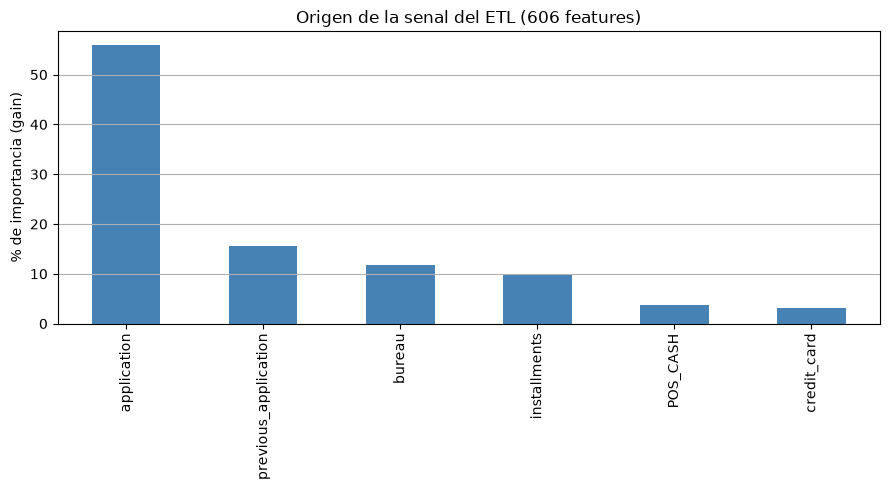

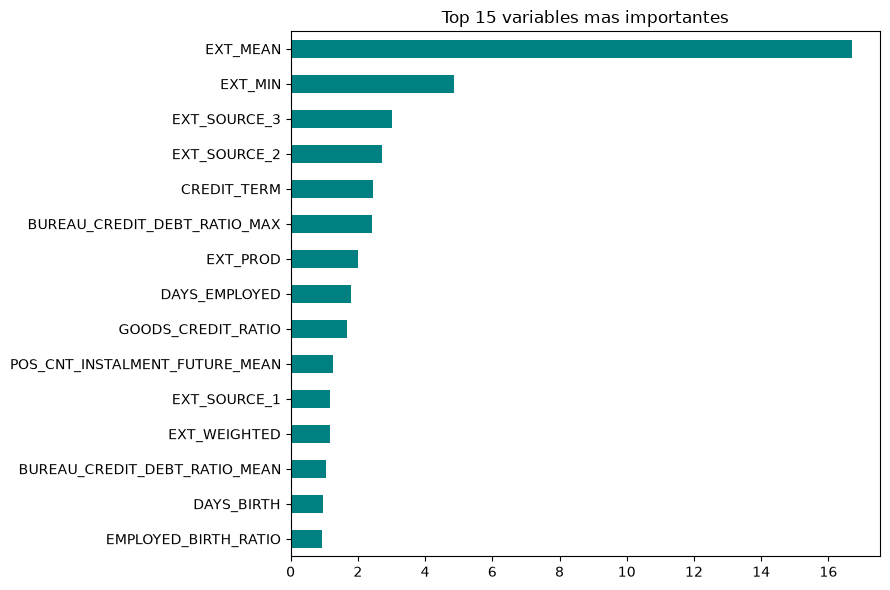

In [14]:
# --- Importancia por tabla de origen (modelo LightGBM seleccionado) ---
feature_names = list(x_lgb_train.columns)


def origen(c):
    for pref, nombre in [("BUREAU_", "bureau"), ("PREV_", "previous_application"),
                         ("POS_", "POS_CASH"), ("CC_", "credit_card"), ("INS_", "installments")]:
        if c.startswith(pref):
            return nombre
    return "application"


importancia_var = pd.Series(mejor_lgb.booster_.feature_importance(importance_type="gain"), index=feature_names)
imp = importancia_var.sort_values(ascending=False)

top = pd.DataFrame({"importancia_%": (imp / imp.sum() * 100).round(2)}).head(20)
top["tabla"] = [origen(c) for c in top.index]
print(top)

por_tabla = imp.groupby([origen(c) for c in imp.index]).sum().mul(100 / imp.sum()).round(1).sort_values(ascending=False)
print("\nImportancia acumulada por tabla de origen (%):")
print(por_tabla)
print("\nVariables con importancia 0:", int((imp == 0).sum()), "de", len(imp))
por_tabla.to_csv(RES_DIR / "parte6_importancia_tabla.csv")

fig, ax = plt.subplots(figsize=(9, 5))
por_tabla.plot(kind="bar", ax=ax, color="steelblue")
ax.set_ylabel("% de importancia (gain)")
ax.set_title("Origen de la senal del ETL (606 features)")
ax.grid(True, axis="y")
fig.tight_layout()
fig.savefig(FIG_DIR / "parte6_importancia_tabla.png", dpi=110)
plt.show()

top.head(15).iloc[::-1]["importancia_%"].plot(kind="barh", figsize=(9, 6), color="teal",
                                              title="Top 15 variables mas importantes")
plt.tight_layout()
plt.savefig(FIG_DIR / "parte6_top15.png", dpi=110)
plt.show()

In [15]:
# --- Comparacion 606 vs 236 features (referencia) ---
AUC_236 = 0.7696  # referencia de la version anterior (solo application_train)
mejor_actual = float(tabla_final["Test AUC"].max())
mejor_nombre = tabla_final["Test AUC"].idxmax()

print(f"Mejor modelo de esta version: {mejor_nombre}")
print(f"  Test AUC (606 features): {mejor_actual:.4f}")
print(f"  Referencia (236 features): {AUC_236:.4f}")
print(f"  Diferencia: {mejor_actual - AUC_236:+.4f}")

# Guardar resumen de resultados
resumen = {
    "mejor_modelo": mejor_nombre,
    "test_auc_606": round(mejor_actual, 4),
    "test_auc_236_referencia": AUC_236,
    "diferencia": round(mejor_actual - AUC_236, 4),
    "n_features": int(N_FEATURES),
    "costo_fn": COST_FN,
    "costo_fp": COST_FP,
}
(RES_DIR / "resumen_final.json").write_text(json.dumps(resumen, indent=2), encoding="utf-8")
print("\nResumen guardado en", (RES_DIR / "resumen_final.json").resolve())
resumen

Mejor modelo de esta version: LightGBM optimizado (TPE)
  Test AUC (606 features): 0.7951
  Referencia (236 features): 0.7696
  Diferencia: +0.0255

Resumen guardado en C:\Users\dfgar\Documents\Unal\2026-2\optimizacion e inteligencia artificial\proyecto\resultados_integrado\resumen_final.json


{'mejor_modelo': 'LightGBM optimizado (TPE)',
 'test_auc_606': 0.7951,
 'test_auc_236_referencia': 0.7696,
 'diferencia': 0.0255,
 'n_features': 605,
 'costo_fn': 10.0,
 'costo_fp': 1.0}

---

## Conclusiones generales

1. **Los datos del ETL son la mayor fuente de mejora.** Pasar de 236 features (solo `application_train`) a las **606 columnas del ETL** (agregando buró, solicitudes previas, POS, tarjeta y cuotas) permitió que el historial externo aporte alrededor del **44 % de la importancia** del modelo. Esto es exactamente lo que la versión anterior dejaba como trabajo futuro.

2. **La optimización del entrenamiento importa.** Con la misma red y el mismo costo por época, los optimizadores adaptativos (Adam, Nadam, AdamW) convergen en muy pocas épocas, mientras que SGD y Adagrad no alcanzan el umbral en 30. Restaurar la mejor época (*early stopping*) y regularizar es parte del proceso.

3. **La búsqueda de hiperparámetros depende del modelo.** Keras Tuner (Random Search, Bayesiana, Hyperband) se satura al nivel del MLP; en cambio **LightGBM + Optuna** sí mejora de forma clara. En datos tabulares el *gradient boosting* suele superar a las redes.

4. **Las búsquedas guiadas son viables; el Grid Search no.** Un Grid Search tendría millones de combinaciones; TPE y Hyperband llegan a la zona buena con 20-30 pruebas.

5. **La decisión correcta es por costo, no por 0.5.** Elegir el umbral que minimiza el costo esperado (un falso negativo cuesta mucho más que un falso positivo) es lo que conecta el modelo con el problema de negocio.

6. **Trabajo futuro:** ensamblar LightGBM con el MLP, calibrar probabilidades, y llevar la evaluación final al `application_test` (score de competencia).

## Referencias

- Home Credit Group. (2018). *Home Credit Default Risk* [Competencia de Kaggle]. https://www.kaggle.com/competitions/home-credit-default-risk
- Géron, A. (2019). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (2.ª ed.). O'Reilly.
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR*.
- Loshchilov, I., & Hutter, F. (2019). Decoupled weight decay regularization. *ICLR*.
- Dozat, T. (2016). Incorporating Nesterov momentum into Adam. *ICLR Workshop*.
- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *JMLR, 13*, 281–305.
- Li, L., Jamieson, K., DeSalvo, G., Rostamizadeh, A., & Talwalkar, A. (2018). Hyperband: A novel bandit-based approach to hyperparameter optimization. *JMLR, 18*(185), 1–52.
- Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *KDD*.
- Ke, G., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *NeurIPS*.
- O'Malley, T., Bursztein, E., Long, J., Chollet, F., Jin, H., Invernizzi, L., et al. (2019). *KerasTuner*. https://github.com/keras-team/keras-tuner